> **Set `USER_AGENT` to your name and email.** SEC may block requests without contact info.

## Apple Inc. (AAPL)
- **CIK:** 0000320193 · **Latest fiscal year end:** 09-26
- **Latest filing used:** 10-K · accession 0000320193-26-000026 · filed 2026-11-03
- **Taxonomy / currency:** us-gaap, USD
- **Shares outstanding (cover page):** 14,532,182,000
- **Data as of:** 2026-11-23

### Annual (millions of reporting currency; shares in millions; EPS per share)

,2021-09-25,2022-09-24,2023-09-30,2024-09-28,2025-09-27,2026-09-26
Revenue,365817.000,394328.000,383285.000,391035.000,416161.000,478834.000
Gross profit,152836.000,170782.000,169148.000,180683.000,195201.000,233602.000
Operating income,108949.000,119437.000,114301.000,123216.000,133050.000,158063.000
Net income,94680.000,99803.000,96995.000,93736.000,112010.000,132175.000
EPS diluted,5.610,6.110,6.130,6.080,7.460,8.980
Diluted shares (avg),16864.919,16325.819,15812.547,15408.095,15004.697,14720.306
Operating cash flow,104038.000,122151.000,110543.000,118254.000,111482.000,145097.000
Capex,11085.000,10708.000,10959.000,9447.000,12715.000,9041.000
Cash,34940.000,23646.000,29965.000,29943.000,35934.000,36305.000
Current assets,134836.000,135405.000,143566.000,152987.000,147957.000,173857.000


### Annual ratios (blank = missing input or zero/negative denominator)

,2021-09-25,2022-09-24,2023-09-30,2024-09-28,2025-09-27,2026-09-26
Revenue growth,NaN,0.078,-0.028,0.020,0.064,0.151
Gross margin,0.418,0.433,0.441,0.462,0.469,0.488
Operating margin,0.298,0.303,0.298,0.315,0.320,0.330
Net margin,0.259,0.253,0.253,0.240,0.269,0.276
ROE (NI / year-end equity),1.501,1.970,1.561,1.646,1.519,1.179
Current ratio,1.075,0.879,0.988,0.867,0.893,1.023
Debt / equity,1.729,1.953,1.533,1.506,1.062,0.608
Free cash flow ($M),92953.000,111443.000,99584.000,108807.000,98767.000,136056.000
FCF margin,0.254,0.283,0.260,0.278,0.237,0.284
Diluted share change,NaN,-0.032,-0.031,-0.026,-0.026,-0.019


... (2 outputs left out)

### Trailing twelve months (sum of last four quarters, $M)

,Gross profit,Net income,Revenue,Operating income,Capex,Operating cash flow
TTM,233602.0,132175.0,478834.0,158063.0,9041.0,145097.0


### Data quality and red flags

- Tags disagree for Long-term debt ending 2021-09-25. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2022-09-24. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2023-09-30. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2024-09-28. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2024-12-28. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2025-03-29. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2025-06-28. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2025-09-27. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2025-12-27. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2026-03-28. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2026-06-27. The highest-priority tag was used.
- Tags disagree for Long-term debt ending 2026-09-26. The highest-priority tag was used.
- Fallback tag for Revenue: RevenueFromContractWithCustomerExcludingAssessedTax (16 period(s)).
- Revenue: 7 quarter(s) derived from year-to-date values.
- Gross profit: 7 quarter(s) derived from year-to-date values.
- Operating income: 19 quarter(s) derived from year-to-date values.
- Net income: 7 quarter(s) derived from year-to-date values.
- Operating cash flow: 48 quarter(s) derived from year-to-date values.
- Capex: 39 quarter(s) derived from year-to-date values.
- Non-GAAP and adjusted figures are excluded: they are not in XBRL facts.
- Text-based risks (going concern, auditor opinion, material weakness) are not checked here. Read the filing.

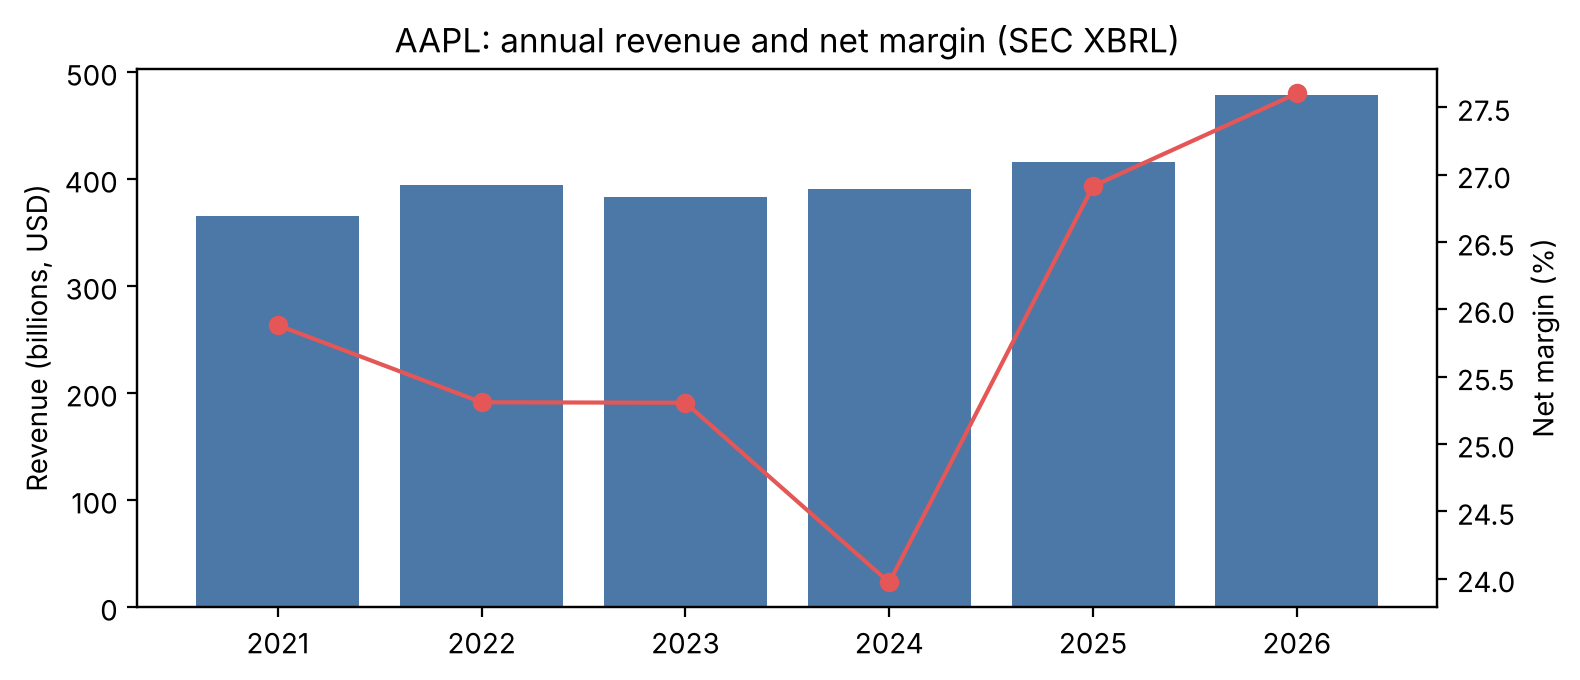

**LLM package written to** `/root/.cache/sec_companyfacts/AAPL_llm_input.txt`. Paste it into any LLM, or use the JSON in your own code.

In [1]:
# =============================================================================
#  SEC FUNDAMENTALS - single cell. Run All.
#  Source: SEC XBRL companyfacts (data.sec.gov). Every number comes from a filing.
#  Nothing is estimated. A missing value shows as blank, never as zero.
# =============================================================================

import json
import time
from datetime import date
from pathlib import Path

import pandas as pd
import requests

# ----------------------------- SETTINGS --------------------------------------
TICKER = "AAPL"                       # any SEC filer: 10-K, 20-F or 40-F
PRICE = None                          # optional share price; enables P/E
USER_AGENT = "FundamentalsNotebook/1.0 Your Name your.email@example.com"  # SEC requires contact info
ANNUAL_YEARS = 6
QUARTERS = 8
CACHE_DIR = Path.home() / ".cache" / "sec_companyfacts"
# -----------------------------------------------------------------------------

try:
    from IPython.display import Markdown, display
except ImportError:                   # plain Python fallback
    Markdown = str

    def display(obj):
        print(obj.to_string() if isinstance(obj, pd.DataFrame) else obj)


def md(text):
    display(Markdown(text))


if "Your Name" in USER_AGENT:
    md("> **Set `USER_AGENT` to your name and email.** SEC may block requests without contact info.")

ANNUAL_FORMS = {"10-K", "10-K/A", "20-F", "20-F/A", "40-F", "40-F/A"}
FORMS = ANNUAL_FORMS | {"10-Q", "10-Q/A"}
# Year-to-date values can be differenced into quarters only for these.
# EPS and share counts are not additive, so their quarters come only from reported 3-month facts.
ADDITIVE = {"Revenue", "Gross profit", "Operating income", "Net income",
            "Operating cash flow", "Capex"}

PER_SHARE = {"EPS diluted"}

# metric: (kind, candidate tags in priority order, unit). "CUR" = reporting currency.
US_CONCEPTS = {
    "Revenue":              ("flow", ["Revenues", "RevenueFromContractWithCustomerExcludingAssessedTax", "SalesRevenueNet"], "USD"),
    "Gross profit":         ("flow", ["GrossProfit"], "USD"),
    "Operating income":     ("flow", ["OperatingIncomeLoss"], "USD"),
    "Net income":           ("flow", ["NetIncomeLoss"], "USD"),
    "EPS diluted":          ("flow", ["EarningsPerShareDiluted"], "USD/shares"),
    "Diluted shares (avg)": ("flow", ["WeightedAverageNumberOfDilutedSharesOutstanding"], "shares"),
    "Operating cash flow":  ("flow", ["NetCashProvidedByUsedInOperatingActivities"], "USD"),
    "Capex":                ("flow", ["PaymentsToAcquirePropertyPlantAndEquipment"], "USD"),
    "Cash":                 ("instant", ["CashAndCashEquivalentsAtCarryingValue"], "USD"),
    "Current assets":       ("instant", ["AssetsCurrent"], "USD"),
    "Total assets":         ("instant", ["Assets"], "USD"),
    "Current liabilities":  ("instant", ["LiabilitiesCurrent"], "USD"),
    "Total liabilities":    ("instant", ["Liabilities"], "USD"),
    "Equity (parent)":      ("instant", ["StockholdersEquity",
                                         "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest"], "USD"),
    "Long-term debt":       ("instant", ["LongTermDebtNoncurrent", "LongTermDebt"], "USD"),
}

# ----------------------------- 1. FETCH --------------------------------------
SESSION = requests.Session()
SESSION.headers["User-Agent"] = USER_AGENT


def get_json(url, tries=4):
    for attempt in range(tries):
        r = SESSION.get(url, timeout=30)
        if r.status_code == 200:
            time.sleep(0.12)          # stay well under SEC's rate limit
            return r.json()
        if r.status_code in (429, 500, 502, 503, 504) and attempt < tries - 1:
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()


def resolve_cik(ticker):
    for row in get_json("https://www.sec.gov/files/company_tickers.json").values():
        if row["ticker"].upper() == ticker.upper():
            return int(row["cik_str"]), row["title"]
    raise ValueError(f"{ticker!r} is not in the SEC ticker map (share classes use a dash, e.g. BRK-B)")


def load_companyfacts(cik):
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    path = CACHE_DIR / f"CIK{cik:010d}.json"
    if path.exists() and time.time() - path.stat().st_mtime < 86400:
        return json.loads(path.read_text())
    data = get_json(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik:010d}.json")
    path.write_text(json.dumps(data))
    return data


# Foreign filers that report under IFRS use the ifrs-full taxonomy, in their own currency
IFRS_CONCEPTS = {
    "Revenue":              ("flow", ["Revenue"], "CUR"),
    "Gross profit":         ("flow", ["GrossProfit"], "CUR"),
    "Operating income":     ("flow", ["ProfitLossFromOperatingActivities"], "CUR"),
    "Net income":           ("flow", ["ProfitLossAttributableToOwnersOfParent", "ProfitLoss"], "CUR"),
    "EPS diluted":          ("flow", ["DilutedEarningsLossPerShare"], "CUR/shares"),
    "Diluted shares (avg)": ("flow", [], "shares"),
    "Operating cash flow":  ("flow", ["CashFlowsFromUsedInOperatingActivities"], "CUR"),
    "Capex":                ("flow", ["PurchaseOfPropertyPlantAndEquipmentClassifiedAsInvestingActivities"], "CUR"),
    "Cash":                 ("instant", ["CashAndCashEquivalents"], "CUR"),
    "Current assets":       ("instant", ["CurrentAssets"], "CUR"),
    "Total assets":         ("instant", ["Assets"], "CUR"),
    "Current liabilities":  ("instant", ["CurrentLiabilities"], "CUR"),
    "Total liabilities":    ("instant", ["Liabilities"], "CUR"),
    "Equity (parent)":      ("instant", ["EquityAttributableToOwnersOfParent", "Equity"], "CUR"),
    "Long-term debt":       ("instant", ["NoncurrentPortionOfNoncurrentBorrowings"], "CUR"),
}

cik, sec_title = resolve_cik(TICKER)
cf = load_companyfacts(cik)
entity = cf.get("entityName", sec_title)
all_facts = cf.get("facts", {})
TAXONOMY = "us-gaap" if "us-gaap" in all_facts else "ifrs-full"
ns = all_facts.get(TAXONOMY, {})
CONCEPTS = US_CONCEPTS if TAXONOMY == "us-gaap" else IFRS_CONCEPTS
CUR = "USD"
if TAXONOMY == "ifrs-full":
    rev_units = ns.get("Revenue", {}).get("units", {})
    CUR = max(rev_units, key=lambda u: len(rev_units[u])) if rev_units else "reporting currency"

# ----------------------------- 2. FACTS -> ONE VALUE PER PERIOD --------------
rows = []
for metric, (kind, tags, unit) in CONCEPTS.items():
    unit_name = unit.replace("CUR", CUR)
    for rank, tag in enumerate(tags):
        for f in ns.get(tag, {}).get("units", {}).get(unit_name, []):
            if f.get("form") in FORMS:
                rows.append(dict(metric=metric, kind=kind, rank=rank, tag=tag,
                                 start=f.get("start"), end=f["end"], val=f["val"],
                                 form=f["form"], filed=f["filed"], accn=f["accn"]))
facts = pd.DataFrame(rows)
if facts.empty:
    raise ValueError("No 10-K / 10-Q / 20-F / 40-F XBRL facts found for this company.")

facts["start"] = pd.to_datetime(facts["start"]).fillna(pd.Timestamp("1900-01-01"))  # instants have no start
facts["end"] = pd.to_datetime(facts["end"])
facts["filed"] = pd.to_datetime(facts["filed"])
facts["days"] = (facts["end"] - facts["start"]).dt.days
facts = facts.sort_values("filed", kind="stable")

# One row per (metric, tag, period): latest value plus evidence of restatement
info = (facts.groupby(["metric", "tag", "start", "end"], sort=False)
        .agg(kind=("kind", "first"), rank=("rank", "first"), days=("days", "first"),
             first_val=("val", "first"), latest_val=("val", "last"),
             n_vals=("val", "nunique"), form=("form", "last"),
             accn=("accn", "last"), filed=("filed", "last"))
        .reset_index())
# Per period keep the highest-priority tag that has a value (handles tag drift)
best = (info.sort_values(["metric", "start", "end", "rank"])
        .drop_duplicates(["metric", "start", "end"], keep="first"))
# Same period, different tags, different values
tag_conflicts = info.groupby(["metric", "start", "end"])["latest_val"].nunique()
tag_conflicts = tag_conflicts[tag_conflicts > 1]

# ----------------------------- 3. PERIOD SERIES ------------------------------
def annual_series(metric):
    kind = CONCEPTS[metric][0]
    b = best[best["metric"] == metric]
    if kind == "flow":
        b = b[b["days"].between(350, 380)]            # full-year durations only
    return b.set_index("end")["latest_val"].groupby(level=0).last()


def quarterly_flow(metric):
    """Reported 3-month values. For additive metrics, Q2-Q4 are also derived from
    year-to-date values: Q2 = 6M - 3M, Q3 = 9M - 6M, Q4 = FY - 9M."""
    b = best[(best["metric"] == metric) & (best["kind"] == "flow") & best["days"].between(60, 400)]
    out = {}
    for _, grp in b.groupby("start"):
        prev = None
        for r in grp.sort_values("end").itertuples():
            if r.days <= 100:
                out[r.end] = (r.latest_val, "reported", f"{r.form} {r.accn}")
            elif prev is not None and metric in ADDITIVE and r.end not in out:
                out[r.end] = (r.latest_val - prev.latest_val, "derived", f"{r.form} {r.accn}")
            prev = r
    return out


flow_metrics = [m for m, (k, _, _) in CONCEPTS.items() if k == "flow"]
annual = {m: annual_series(m) for m in CONCEPTS}
ann_ends = sorted(set().union(*[annual[m].index for m in flow_metrics]))[-ANNUAL_YEARS:]
annual_wide = pd.DataFrame({m: annual[m].reindex(ann_ends) for m in CONCEPTS},
                           index=pd.DatetimeIndex(ann_ends))

qflows = {m: quarterly_flow(m) for m in flow_metrics}
q_ends = sorted(set().union(*[set(d.keys()) for d in qflows.values()]))[-QUARTERS:]
q_wide = pd.DataFrame(index=pd.DatetimeIndex(q_ends))
for m in CONCEPTS:
    if CONCEPTS[m][0] == "flow":
        q_wide[m] = [qflows[m][e][0] if e in qflows[m] else float("nan") for e in q_ends]
    else:
        q_wide[m] = annual[m].reindex(q_ends).values

ttm = None
if len(q_wide) >= 4:
    last4 = q_wide.iloc[-4:]
    if 255 <= (last4.index[-1] - last4.index[0]).days <= 300:   # four consecutive quarters
        ttm = last4[list(ADDITIVE)].sum(min_count=4)

# ----------------------------- 4. RATIOS & TABLES ----------------------------
def table(df, scale=False):
    out = df.copy()
    if scale:
        for m in out.columns:
            if m not in PER_SHARE:
                out[m] = out[m] / 1e6
    out.index = [d.strftime("%Y-%m-%d") for d in out.index]
    return out.T.round(3)


def ratios(w):
    rev = w["Revenue"].where(w["Revenue"] > 0)
    eq = w["Equity (parent)"].where(w["Equity (parent)"] > 0)
    cl = w["Current liabilities"].where(w["Current liabilities"] > 0)
    fcf = w["Operating cash flow"] - w["Capex"].abs()
    sh = w["Diluted shares (avg)"]
    r = pd.DataFrame(index=w.index)
    r["Revenue growth"] = w["Revenue"] / w["Revenue"].shift(1) - 1
    r["Gross margin"] = w["Gross profit"] / rev
    r["Operating margin"] = w["Operating income"] / rev
    r["Net margin"] = w["Net income"] / rev
    r["ROE (NI / year-end equity)"] = w["Net income"] / eq
    r["Current ratio"] = w["Current assets"] / cl
    r["Debt / equity"] = w["Long-term debt"] / eq
    r["Free cash flow ($M)"] = fcf / 1e6
    r["FCF margin"] = fcf / rev
    r["Diluted share change"] = sh / sh.shift(1) - 1
    if PRICE:
        eps = w["EPS diluted"].where(w["EPS diluted"] > 0)   # P/E is NM on zero or negative EPS
        r["P/E at PRICE"] = PRICE / eps
    return r


ratios_df = ratios(annual_wide)

# ----------------------------- 5. DATA QUALITY & RED FLAGS -------------------
flags = []
today = pd.Timestamp(date.today())
newest = best["end"].max()
if (today - newest).days > 135:
    flags.append(f"Newest period ends {newest:%Y-%m-%d}, more than 135 days ago. Check EDGAR for a newer filing.")

# Only periods shown above; older history is noise for this view
WINDOW = set(ann_ends) | set(q_ends)
recent = best[best["end"].isin(WINDOW)]


def money(v):
    return f"{v / 1e6:,.1f}M" if abs(v) >= 1e5 else f"{v:,.2f}"


for r in recent[recent["n_vals"] > 1].itertuples():
    ratio = r.latest_val / r.first_val if r.first_val else float("nan")
    k = max(ratio, 1 / ratio) if ratio and ratio > 0 else float("nan")
    note = ""
    if r.metric in ("EPS diluted", "Diluted shares (avg)") and k > 1.5 and abs(k - round(k)) < 0.02:
        note = f" Ratio {round(k)}:1 looks like a stock split, so per-share history was restated."
    flags.append(f"Restated/revised {r.metric} for {r.end:%Y-%m-%d}: first filed {money(r.first_val)} -> "
                 f"latest {money(r.latest_val)} ({r.form} {r.accn}).{note}")

for (metric, _, end), _n in tag_conflicts.items():
    if end in WINDOW:
        flags.append(f"Tags disagree for {metric} ending {end:%Y-%m-%d}. The highest-priority tag was used.")

amended = recent[recent["form"].str.endswith("/A")]
if len(amended):
    flags.append("Amended filings in use: " + ", ".join(sorted(set(amended["accn"])))
                 + ". Confirm each amendment is a full restatement.")

for m, g in recent[recent["rank"] > 0].groupby("metric"):
    flags.append(f"Fallback tag for {m}: {g['tag'].iloc[-1]} ({len(g)} period(s)).")

for m, d in qflows.items():
    n_der = sum(1 for v in d.values() if v[1] == "derived")
    if n_der:
        flags.append(f"{m}: {n_der} quarter(s) derived from year-to-date values.")

missing = [m for m in CONCEPTS if annual_wide[m].isna().all()]
if missing:
    flags.append("No annual XBRL data for: " + ", ".join(missing) + ". Shown blank, not zero.")

gaap_tags = set(ns)
if TAXONOMY == "ifrs-full":
    flags.append(f"IFRS filer ({CUR}). Values are in reporting currency, and diluted share counts are not tagged.")
if gaap_tags & {"Deposits", "InterestAndDividendIncomeOperating"}:
    flags.append("Bank-style filer. Revenue, gross margin and current ratio are not comparable. Use a bank template.")
if "PremiumsEarnedNet" in gaap_tags:
    flags.append("Insurer-style filer. Use insurance metrics (loss ratio, combined ratio, book value).")
if "RealEstateInvestmentPropertyNet" in gaap_tags:
    flags.append("Real-estate-heavy filer. Consider REIT metrics (FFO, AFFO).")

if len(annual_wide):
    last = annual_wide.iloc[-1]
    if last["Net income"] < 0:
        flags.append("Net loss in latest fiscal year.")
    if last["Equity (parent)"] < 0:
        flags.append("Negative parent equity: ROE and debt/equity are not meaningful.")
    fcf_last = last["Operating cash flow"] - abs(last["Capex"])
    if pd.notna(fcf_last) and fcf_last < 0:
        flags.append("Negative free cash flow in latest fiscal year.")
    sh = annual_wide["Diluted shares (avg)"].dropna()
    if len(sh) >= 2 and sh.iloc[-1] / sh.iloc[-2] - 1 > 0.05:
        flags.append("Diluted share count up more than 5% year over year (dilution).")

flags.append("Non-GAAP and adjusted figures are excluded: they are not in XBRL facts.")
flags.append("Text-based risks (going concern, auditor opinion, material weakness) are not checked here. Read the filing.")

# ----------------------------- 6. DISPLAY ------------------------------------
lf = best.loc[best["filed"].idxmax()]
dei_shares = cf.get("facts", {}).get("dei", {}).get("EntityCommonStockSharesOutstanding", {}).get("units", {}).get("shares", [])
so_txt = f"{max(dei_shares, key=lambda f: f['end'])['val']:,.0f}" if dei_shares else "not reported"
fy_txt = ann_ends[-1].strftime("%m-%d") if len(ann_ends) else "n/a"

md(f"""## {entity} ({TICKER})
- **CIK:** {cik:010d} · **Latest fiscal year end:** {fy_txt}
- **Latest filing used:** {lf.form} · accession {lf.accn} · filed {lf.filed:%Y-%m-%d}
- **Taxonomy / currency:** {TAXONOMY}, {CUR}
- **Shares outstanding (cover page):** {so_txt}
- **Data as of:** {date.today():%Y-%m-%d}""")

md("### Annual (millions of reporting currency; shares in millions; EPS per share)")
display(table(annual_wide, scale=True))

md("### Annual ratios (blank = missing input or zero/negative denominator)")
display(table(ratios_df))

if len(q_wide) and q_wide.notna().any().any():
    md("### Quarterly (millions of reporting currency; shares in millions; EPS per share)")
    display(table(q_wide, scale=True))
else:
    md("_No quarterly data in this filer's facts. Annual-only filers (20-F, 40-F, some small companies) report only full years._")

if ttm is not None:
    md("### Trailing twelve months (sum of last four quarters, $M)")
    display((ttm / 1e6).round(2).to_frame("TTM").T)

md("### Data quality and red flags")
md("\n".join(f"- {f}" for f in flags))

try:
    import matplotlib.pyplot as plt
    labels = [d.strftime("%Y") for d in annual_wide.index]
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.bar(labels, annual_wide["Revenue"].values / 1e9, color="#4C78A8")
    ax.set_ylabel(f"Revenue (billions, {CUR})")
    ax2 = ax.twinx()
    ax2.plot(labels, ratios_df["Net margin"].values * 100, color="#E45756", marker="o")
    ax2.set_ylabel("Net margin (%)")
    ax.set_title(f"{TICKER}: annual revenue and net margin (SEC XBRL)")
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

# ----------------------------- 7. LLM PACKAGE --------------------------------
def jsonable(df):
    d = df.copy()
    d.index = [i.strftime("%Y-%m-%d") for i in d.index]
    return {c: {i: (None if pd.isna(v) else round(float(v), 6)) for i, v in d[c].items()} for c in d.columns}


quarterly_detail = [
    {"metric": m, "period_end": e.strftime("%Y-%m-%d"), "value": round(float(v), 2),
     "method": method, "source": src}
    for m, d in qflows.items() for e, (v, method, src) in sorted(d.items()) if e in q_ends
]

LLM_PROMPT = """You are a financial analyst. Write a fundamentals summary for one public company using ONLY the JSON below, which was extracted from SEC XBRL filings.
Rules:
- Use only the JSON. Never estimate or recall a number. A null value means not reported, not zero.
- Cite the form and accession number for each figure you quote (see filings_used).
- Blank ratios mean a missing input or a zero/negative denominator. Write "NM" for those.
- quarterly_detail gives the method for each quarter. Say when a quarter was derived from year-to-date values.
- Do not present non-GAAP figures as GAAP. None are included here.
- Read data_quality_and_red_flags first. Mention each flag that affects the conclusion.
- Output, in order: header (company, ticker, CIK, latest filing, as-of date); annual income statement and cash flow; balance sheet (latest year); ratios; data-quality notes; red flags; a summary of at most five sentences. No price targets, buy/sell calls or forecasts.
- If a section cannot be answered from the JSON, say so and stop there."""

filings_used = sorted(set(f"{f} {a} (filed {p:%Y-%m-%d})"
                          for f, a, p in zip(recent["form"], recent["accn"], recent["filed"])))
payload = {
    "company": entity, "ticker": TICKER, "cik": f"{cik:010d}", "as_of": str(date.today()),
    "latest_filing": {"form": lf.form, "accession": lf.accn, "filed": f"{lf.filed:%Y-%m-%d}"},
    "filings_used": filings_used,
    "annual_raw_usd_or_shares": jsonable(annual_wide),
    "annual_ratios": jsonable(ratios_df),
    "quarterly_detail": quarterly_detail,
    "data_quality_and_red_flags": flags,
}
out_path = CACHE_DIR / f"{TICKER}_llm_input.txt"
out_path.write_text(LLM_PROMPT + "\n\nINPUT JSON:\n" + json.dumps(payload, indent=2))
md(f"**LLM package written to** `{out_path}`. Paste it into any LLM, or use the JSON in your own code.")
